# Superstore Retail Sales: Python EDA

**Dataset:** 5,901 order line items, Jan 2019 to Dec 2020 (4 regions, 3 categories, 17 sub-categories).
**Goal:** understand sales and profit drivers, and find out why profit margin fell in 2020.
**Tools:** pandas, NumPy, matplotlib, seaborn, SciPy.
**Note:** keep `superstore_cleaned.csv` in the same folder as this notebook, then use Restart & Run All.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## EDA

In [2]:
# Keep superstore_cleaned.csv in the same folder as this notebook
df=pd.read_csv("superstore_cleaned.csv")

In [3]:
df.shape

(5901, 24)

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,Profit Margin,Shipping Days,Order Month
0,4918,CA-2019-160304,01-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",73.94,1,28.2668,NaN,Online,38%,6,Jan-2019
1,4919,CA-2019-160304,02-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",173.94,3,38.2668,NaN,Online,22%,5,Jan-2019
2,4920,CA-2019-160304,02-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Phones,GE 30522EE2,231.98,2,67.2742,NaN,Cards,29%,5,Jan-2019
3,3074,CA-2019-125206,03-01-2019,05-01-2019,First Class,LR-16915,Lena Radford,Consumer,United States,Los Angeles,...,Storage,Recycled Steel Personal File for Hanging File ...,114.46,2,28.6150,NaN,Online,25%,2,Jan-2019
4,8604,US-2019-116365,03-01-2019,08-01-2019,Standard Class,CA-12310,Christine Abelman,Corporate,United States,San Antonio,...,Accessories,Imation Clip USB flash drive - 8 GB,30.08,2,-5.2640,NaN,Online,-18%,5,Jan-2019


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5901 entries, 0 to 5900
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         5901 non-null   int64  
 1   Order ID       5901 non-null   object 
 2   Order Date     5901 non-null   object 
 3   Ship Date      5901 non-null   object 
 4   Ship Mode      5901 non-null   object 
 5   Customer ID    5901 non-null   object 
 6   Customer Name  5901 non-null   object 
 7   Segment        5901 non-null   object 
 8   Country        5901 non-null   object 
 9   City           5901 non-null   object 
 10  State          5901 non-null   object 
 11  Region         5901 non-null   object 
 12  Product ID     5901 non-null   object 
 13  Category       5901 non-null   object 
 14  Sub-Category   5901 non-null   object 
 15  Product Name   5901 non-null   object 
 16  Sales          5901 non-null   float64
 17  Quantity       5901 non-null   int64  
 18  Profit  

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,5901.0,5022.422471,2877.977184,1.000,2486.0000,5091.0000,7456.000,9994.000
Sales,5901.0,265.345589,474.260645,0.836,71.9760,128.6480,265.170,9099.930
Quantity,5901.0,3.781901,2.212917,1.000,2.0000,3.0000,5.000,14.000
Profit,5901.0,29.700408,259.589138,-6599.978,1.7955,8.5025,28.615,8399.976
Returns,287.0,1.000000,0.000000,1.000,1.0000,1.0000,1.000,1.000
Shipping Days,5901.0,3.926962,1.792050,0.000,3.0000,4.0000,5.000,8.000


In [7]:
df.describe(include='object').T

,count,unique,top,freq
Order ID,5901,3003,CA-2020-100111,14
Order Date,5901,643,05-09-2019,38
Ship Date,5901,690,26-09-2020,34
Ship Mode,5901,4,Standard Class,3451
Customer ID,5901,773,EP-13915,27
Customer Name,5901,773,Emily Phan,27
Segment,5901,3,Consumer,2997
Country,5901,1,United States,5901
City,5901,452,New York City,563
State,5901,49,California,1189


## Univariate 

In [8]:
print(df.select_dtypes(include=["object"]).columns)

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region',
       'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Payment Mode', 'Profit Margin', 'Order Month'],
      dtype='object')


In [9]:
# Convert date type in dateformat

In [10]:
df[['Order Date','Ship Date']].head()

,Order Date,Ship Date
0,01-01-2019,07-01-2019
1,02-01-2019,07-01-2019
2,02-01-2019,07-01-2019
3,03-01-2019,05-01-2019
4,03-01-2019,08-01-2019


In [11]:
df['Order Date']=pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y',
    errors='coerce'
)
    

In [12]:
df['Ship Date']=pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [13]:
# convert profit margin type in numerical

In [14]:
df['Profit Margin']=(
    df['Profit Margin']
    .astype(str)
    .str.replace('%', '', regex=False)
)

df['Profit Margin'] = pd.to_numeric(
    df['Profit Margin'],
    errors='coerce'
)
    


In [15]:
# convert order month in date type 

In [16]:
df['Order Month'] = pd.to_datetime(
    df['Order Month'],
    format='%b-%Y',
    errors='coerce'
)

In [17]:
# Seperating categorical and numerical columns
print(df.select_dtypes(include=["object"]).columns)
print(df.select_dtypes(exclude=["object"]).columns)

Index(['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment',
       'Country', 'City', 'State', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Payment Mode'],
      dtype='object')
Index(['Row ID', 'Order Date', 'Ship Date', 'Sales', 'Quantity', 'Profit',
       'Returns', 'Profit Margin', 'Shipping Days', 'Order Month'],
      dtype='object')


In [18]:
def cat_univariate(data,x):

    miss=data[x].isnull().sum()
    unique=data[x].nunique()
    mode=data[x].mode()[0]
    freq=data[x].value_counts()
    percent=data[x].value_counts(normalize=True)*100

    result=pd.DataFrame({
        'Frequency': freq,
        'Percentage': percent.round(2)
    })

    print("Missing values",miss)
    print("Unique Categories:", unique)
    print("Mode:", mode)

    display(result)

    sns.countplot(data=data,x=x,order=freq.index)
    plt.xticks(rotation=45)
    plt.show()
    
    

Missing values 0
Unique Categories: 3
Mode: Consumer


,Frequency,Percentage
Segment,,
Consumer,2997,50.79
Corporate,1774,30.06
Home Office,1130,19.15


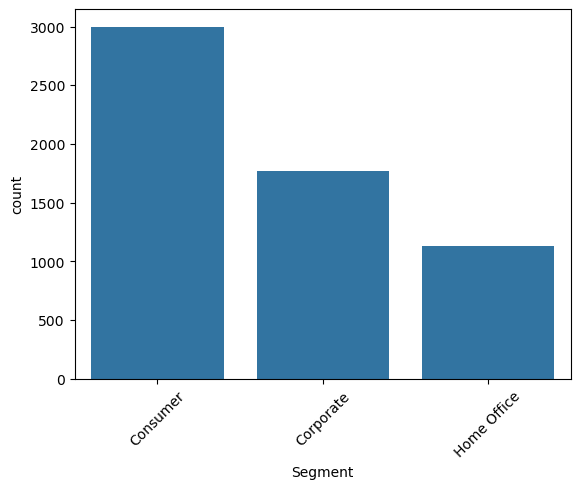

In [19]:
cat_univariate(df,'Segment')

## Numerical columns

In [20]:
print(df.select_dtypes(exclude="object").columns)

Index(['Row ID', 'Order Date', 'Ship Date', 'Sales', 'Quantity', 'Profit',
       'Returns', 'Profit Margin', 'Shipping Days', 'Order Month'],
      dtype='object')


In [62]:
def num_univariate(data, x):

    # 1. Count and missing values
    count = data[x].count()
    miss = data[x].isnull().sum()
    missing_pct = (miss / len(data)) * 100

    # 2. Minimum, maximum and range
    min_val = data[x].min()
    max_val = data[x].max()
    range_val = max_val - min_val

    # 3. Central tendency
    mean = data[x].mean()
    median = data[x].median()

    # 4. Quartiles
    q1 = data[x].quantile(0.25)
    q2 = data[x].quantile(0.50)
    q3 = data[x].quantile(0.75)

    # 5. IQR and outlier boundaries
    iqr = q3 - q1

    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)

    # 6. Outlier counts
    lower_outliers = (data[x] < lower).sum()
    upper_outliers = (data[x] > upper).sum()

    outliers = lower_outliers + upper_outliers

    # 7. Variance and standard deviation
    var = data[x].var()
    std = data[x].std()

    # 8. Coefficient of variation
    cv = (std / mean) * 100 if mean != 0 else np.nan

    # 9. Skewness and kurtosis
    skew = data[x].skew()
    kurt = data[x].kurtosis()

    # 10. Histogram
    sns.histplot(data[x].dropna(), kde=True)
    plt.title(f'Distribution of {x}')
    plt.show()

    # 11. Boxplot
    sns.boxplot(data=data, x=x)
    plt.title(f'Boxplot of {x}')
    plt.show()

    # 12. Result summary
    result = pd.DataFrame(
        [
            count, miss, missing_pct,
            min_val, max_val, range_val,
            mean, median,
            q1, q2, q3, iqr,
            lower, upper,
            lower_outliers, upper_outliers, outliers,
            var, std, cv, skew, kurt
        ],
        index=[
            'count', 'miss', 'missing_pct',
            'min', 'max', 'range',
            'mean', 'median',
            'q1', 'q2', 'q3', 'iqr',
            'lower_bound', 'upper_bound',
            'lower_outliers', 'upper_outliers', 'total_outliers',
            'var', 'std', 'cv', 'skew', 'kurt'
        ]
    )

    return result.T

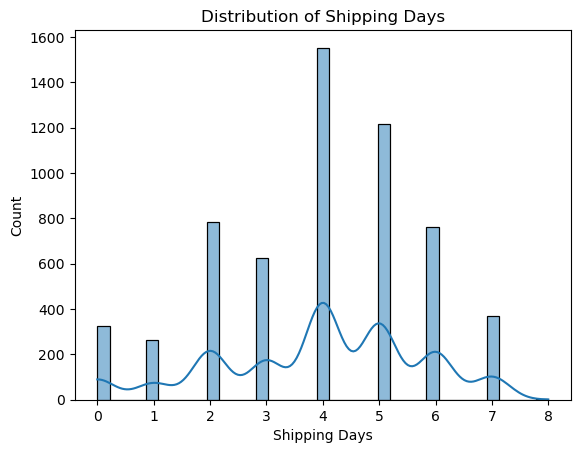

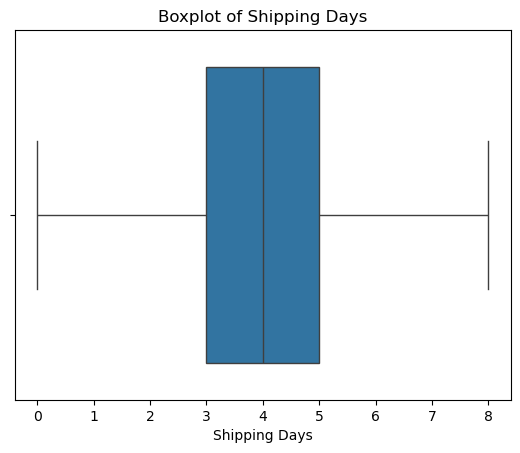

,count,miss,missing_pct,min,max,range,mean,median,q1,q2,...,lower_bound,upper_bound,lower_outliers,upper_outliers,total_outliers,var,std,cv,skew,kurt
0,5901.0,0.0,0.0,0.0,8.0,8.0,3.926962,4.0,3.0,4.0,...,0.0,8.0,0.0,0.0,0.0,3.211444,1.79205,45.634525,-0.393037,-0.412245


In [65]:
num_univariate(df,"Shipping Days")

In [26]:
first_date=df['Order Date'].min()
last_date=df['Order Date'].max()

print("Data First Date:",first_date)
print("Data Last Date:",last_date)

Data First Date: 2019-01-01 00:00:00
Data Last Date: 2020-12-31 00:00:00


## Bivariate Analysis.

### cat-cat

In [54]:
cross=pd.crosstab(df["Region"],df["Payment Mode"])
cross

Payment Mode,COD,Cards,Online
Region,,,
Central,547,297,537
East,697,399,592
South,432,201,298
West,777,387,737


In [55]:
from scipy.stats import chi2_contingency

table = cross

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-Square:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square: 22.08989707487843
P-value: 0.001166280183230797
Degrees of Freedom: 6


In [56]:
print("Chi-square:", chi2)
print("P-value:", p_value)
print("Expected frequencies below 5:", (expected < 5).sum())
print("Total expected cells:", expected.size)
print(
    "Percentage below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

Chi-square: 22.08989707487843
P-value: 0.001166280183230797
Expected frequencies below 5: 0
Total expected cells: 12
Percentage below 5: 0.0 %


In [58]:
import numpy as np

n = table.to_numpy().sum()
r, k = table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.04326324002202945


### cat-num

In [33]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Sales', 'Quantity', 'Profit', 'Returns', 'Payment Mode',
       'Profit Margin', 'Shipping Days', 'Order Month'],
      dtype='object')

In [34]:
df.groupby(['Quantity']).agg({"Profit":["mean","min","max","count"]})

Profit                            
                mean        min        max count
Quantity                                        
1           8.390398  -153.2024   635.4950   563
2          14.325998  -412.6154   843.1706  1397
3          23.972195 -1143.8910  5039.9856  1392
4          41.426830 -3839.9904  6719.9808   703
5          39.965957 -6599.9780  8399.9760   764
6          18.980363 -2287.7820  1453.1238   305
7          40.955078 -1049.3406  2400.9657   362
8          70.887819  -363.5280  1459.2000   177
9          74.503210  -630.8820  2591.9568   151
10         46.125621  -292.1000   386.8350    29
11        175.244231   -52.5481   767.2005    16
12          7.990286  -619.5960   375.4296    14
13        552.357700   -22.8956  4946.3700    13
14        110.173467   -25.5920   510.6360    15

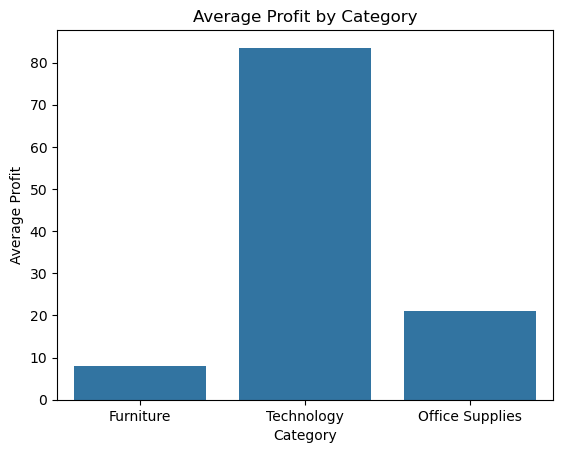

In [35]:
sns.barplot(data=df, x='Category', y='Profit', estimator='mean', errorbar=None)

plt.title('Average Profit by Category')
plt.xlabel('Category')
plt.ylabel('Average Profit')
plt.show()

### num-num

In [36]:
num_cols = [
    'Sales',
    'Profit',
    'Quantity',
    'Profit Margin',
    'Shipping Days'
]

corr = df[num_cols].corr()

display(corr)

,Sales,Profit,Quantity,Profit Margin,Shipping Days
Sales,1.000000,0.325915,0.202420,0.013573,-0.003283
Profit,0.325915,1.000000,0.074761,0.465781,-0.008532
Quantity,0.202420,0.074761,1.000000,0.031146,0.024105
Profit Margin,0.013573,0.465781,0.031146,1.000000,-0.001885
Shipping Days,-0.003283,-0.008532,0.024105,-0.001885,1.000000


## scatter plot

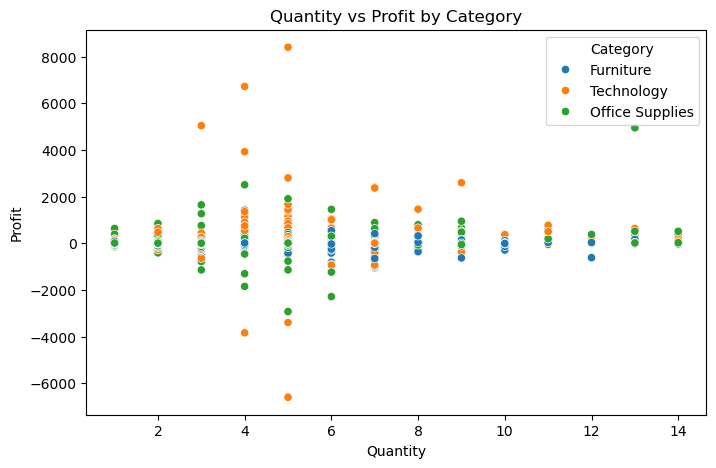

In [37]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Profit',
    hue='Category'
)

plt.title('Quantity vs Profit by Category')
plt.show()

## Correlation Analysis

In [59]:
num_col=[
    'Sales',
    'Profit',
    'Quantity',
    'Profit Margin',
    'Shipping Days'
]

corr=df[num_col].corr(method='pearson')
display(corr)

,Sales,Profit,Quantity,Profit Margin,Shipping Days
Sales,1.000000,0.325915,0.202420,0.013573,-0.003283
Profit,0.325915,1.000000,0.074761,0.465781,-0.008532
Quantity,0.202420,0.074761,1.000000,0.031146,0.024105
Profit Margin,0.013573,0.465781,0.031146,1.000000,-0.001885
Shipping Days,-0.003283,-0.008532,0.024105,-0.001885,1.000000


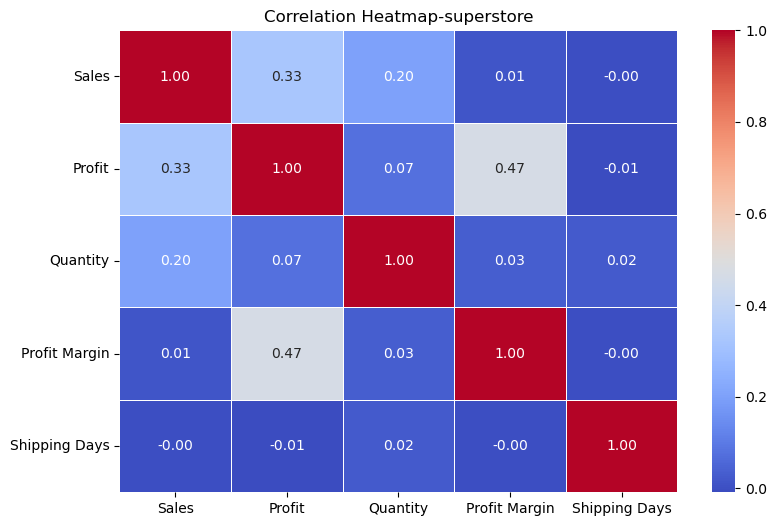

In [60]:
plt.figure(figsize=(9,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidth=.5
)
plt.title('Correlation Heatmap-superstore')
plt.show()

In [40]:
corr_spearman = df[num_cols].corr(method='spearman')

display(corr_spearman)

,Sales,Profit,Quantity,Profit Margin,Shipping Days
Sales,1.000000,0.365143,0.223616,-0.192503,-0.012180
Profit,0.365143,1.000000,0.237335,0.712953,-0.012465
Quantity,0.223616,0.237335,1.000000,0.103573,0.020096
Profit Margin,-0.192503,0.712953,0.103573,1.000000,-0.001833
Shipping Days,-0.012180,-0.012465,0.020096,-0.001833,1.000000


In [41]:
num_cols = [
    'Sales',
    'Profit',
    'Quantity',
    'Profit Margin',
    'Shipping Days'
]

corr_pearson = df[num_cols].corr(method='pearson')
corr_spearman = df[num_cols].corr(method='spearman')

In [42]:
corr_pearson = df[num_cols].corr(method='pearson')
corr_spearman = df[num_cols].corr(method='spearman')

print("Pearson Correlation:")
display(corr_pearson)

print("Spearman Correlation:")
display(corr_spearman)

Pearson Correlation:


,Sales,Profit,Quantity,Profit Margin,Shipping Days
Sales,1.000000,0.325915,0.202420,0.013573,-0.003283
Profit,0.325915,1.000000,0.074761,0.465781,-0.008532
Quantity,0.202420,0.074761,1.000000,0.031146,0.024105
Profit Margin,0.013573,0.465781,0.031146,1.000000,-0.001885
Shipping Days,-0.003283,-0.008532,0.024105,-0.001885,1.000000


Spearman Correlation:


,Sales,Profit,Quantity,Profit Margin,Shipping Days
Sales,1.000000,0.365143,0.223616,-0.192503,-0.012180
Profit,0.365143,1.000000,0.237335,0.712953,-0.012465
Quantity,0.223616,0.237335,1.000000,0.103573,0.020096
Profit Margin,-0.192503,0.712953,0.103573,1.000000,-0.001833
Shipping Days,-0.012180,-0.012465,0.020096,-0.001833,1.000000


## Multivariate Analysis

In [43]:
multi=df.groupby(
    ['Category','Region']
).agg(
     Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).round(2)

display(multi)

Total_Sales  Average_Sales  Total_Profit  \
Category        Region                                              
Furniture       Central    105505.45         370.19      -1534.79   
                East       117071.97         326.11       3621.50   
                South       72984.87         376.21       2562.02   
                West       155946.35         379.43       5357.88   
Office Supplies Central    150154.35         176.24       6477.63   
                East       189066.82         186.09      23248.61   
                South       99652.14         176.06      11104.98   
                West       204834.37         180.47      33966.03   
Technology      Central     85347.72         349.79      22507.17   
                East       144095.87         460.37      26530.31   
                South       79484.07         464.82      12884.72   
                West       161660.33         455.38      28536.05   

                         Average_Profit  
Category        Region                   
Furniture       Central           -5.39  
                East              10.09  
                South             13.21  
                West              13.04  
Office Supplies Central            7.60  
                East              22.88  
                South             19.62  
                West              29.93  
Technology      Central           92.24  
                East              84.76  
                South             75.35  
                West              80.38

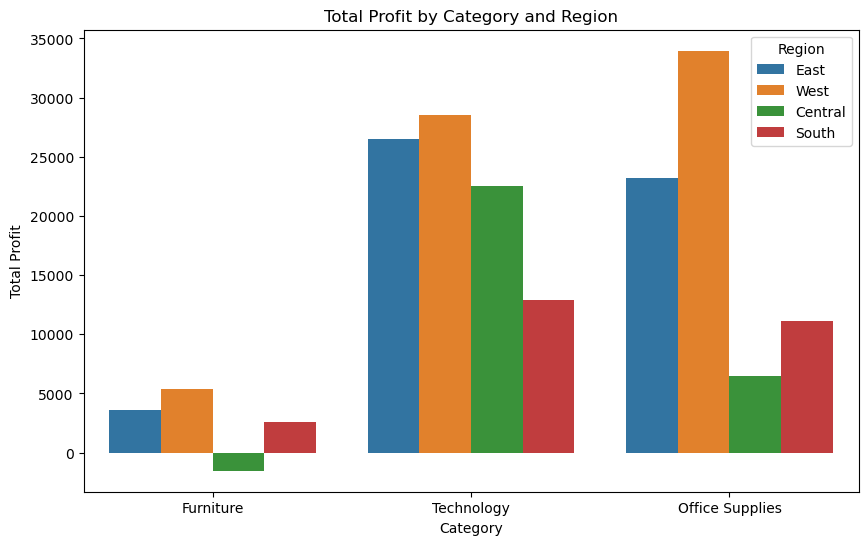

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Category',
    y='Profit',
    hue='Region',
    estimator='sum',
    errorbar=None
)

plt.title('Total Profit by Category and Region')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.legend(title='Region')
plt.show()

In [47]:
multi_1=df.groupby(
    ['Category','Segment']
).agg(
     Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).round(2)

display(multi_1)

Total_Sales  Average_Sales  Total_Profit  \
Category        Segment                                                 
Furniture       Consumer       229508.41         356.38       6677.38   
                Corporate      149110.37         387.30       4285.47   
                Home Office     72889.87         331.32       -956.24   
Office Supplies Consumer       312665.11         170.86      33942.70   
                Corporate      209953.03         198.63      24644.78   
                Home Office    121089.54         177.55      16209.77   
Technology      Consumer       210828.60         403.11      40718.51   
                Corporate      150679.73         453.85      28875.55   
                Home Office    109079.66         478.42      20864.19   

                             Average_Profit  
Category        Segment                      
Furniture       Consumer              10.37  
                Corporate             11.13  
                Home Office           -4.35  
Office Supplies Consumer              18.55  
                Corporate             23.32  
                Home Office           23.77  
Technology      Consumer              77.86  
                Corporate             86.97  
                Home Office           91.51

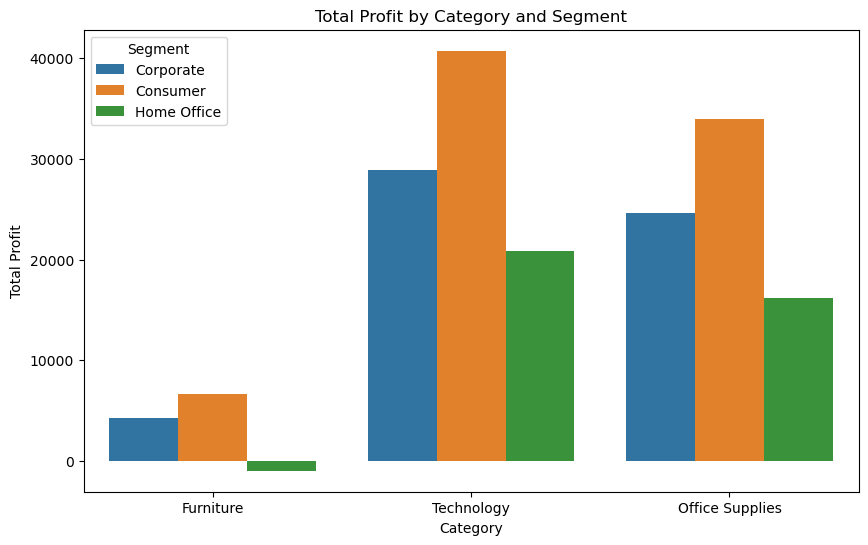

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Category',
    y='Profit',
    hue='Segment',
    estimator='sum',
    errorbar=None
)

plt.title('Total Profit by Category and Segment')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.legend(title='Segment')
plt.show()

## Monthly Sales Trends

In [49]:
# monthly sales
monthly_sales=df.groupby("Order Month")["Sales"].sum().reset_index()

# Sort by date
monthly_sales=monthly_sales.sort_values("Order Month")

# display results
display(monthly_sales)

,Order Month,Sales
0,2019-01-01,18616.4310
1,2019-02-01,19978.8150
2,2019-03-01,51715.8750
3,2019-04-01,38750.0390
4,2019-05-01,50987.7280
5,2019-06-01,40344.5340
6,2019-07-01,39261.9630
7,2019-08-01,31115.3743
8,2019-09-01,73410.0249
9,2019-10-01,42687.7450


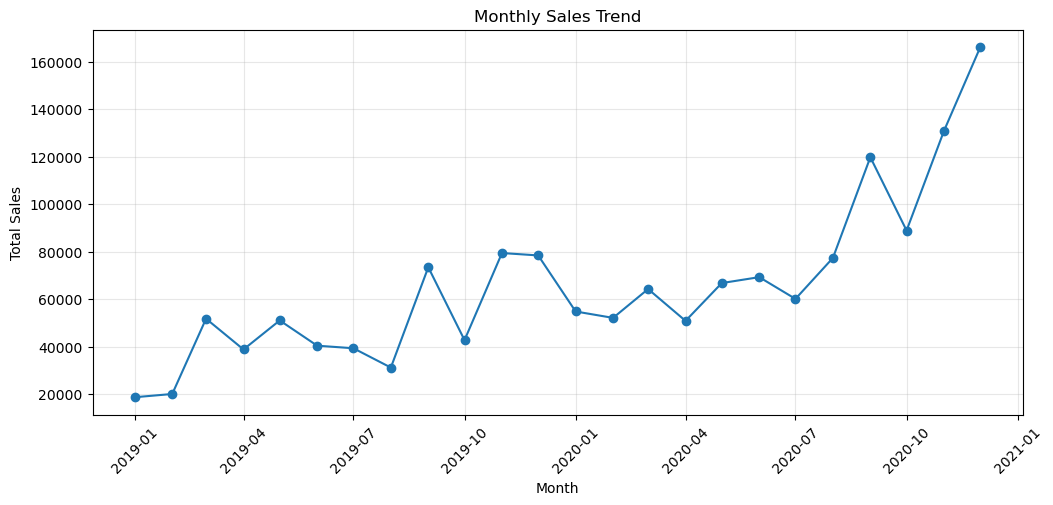

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['Order Month'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

## Monthly Profit Trends

In [51]:
# monthly profit
monthly_profit=df.groupby("Order Month")["Profit"].sum().reset_index()

# Sort by date
monthly_profit=monthly_profit.sort_values("Order Month")

# display results
display(monthly_profit)

,Order Month,Profit
0,2019-01-01,2853.0901
1,2019-02-01,5004.5795
2,2019-03-01,3611.9680
3,2019-04-01,2977.8149
4,2019-05-01,8662.1464
5,2019-06-01,4750.3781
6,2019-07-01,4432.8779
7,2019-08-01,2062.0693
8,2019-09-01,9328.6576
9,2019-10-01,16243.1425


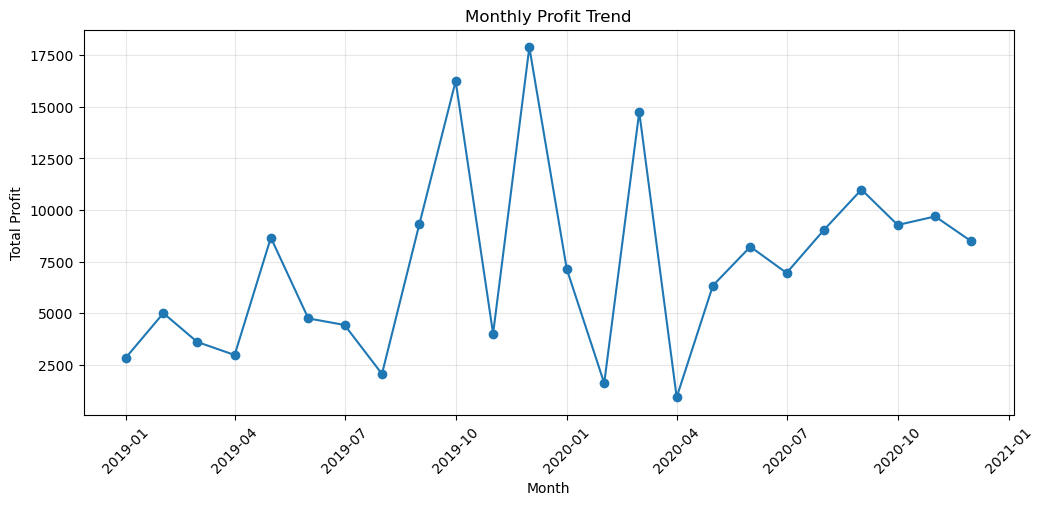

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_profit['Order Month'],
    monthly_profit['Profit'],
    marker='o'
)

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

## yearly sales and profit

In [53]:
yearly_performance = df.groupby(
    df['Order Date'].dt.year
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

yearly_performance.rename(
    columns={'Order Date': 'Year'},
    inplace=True
)

display(yearly_performance.round(2))

,Year,Total_Sales,Total_Profit
0,2019,564679.54,81823.44
1,2020,1001124.79,93438.66


## Missing Values Analysis

In [66]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Total records
print("\nTotal Records:", len(df))

Missing Values:
Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Profit              0
Returns          5614
Payment Mode        0
Profit Margin       0
Shipping Days       0
Order Month         0
dtype: int64

Duplicate Rows: 0

Total Records: 5901


In [69]:
df[df["Returns"]!=1].head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,Profit Margin,Shipping Days,Order Month
0,4918,CA-2019-160304,2019-01-01,2019-01-07,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",73.94,1,28.2668,NaN,Online,38,6,2019-01-01
1,4919,CA-2019-160304,2019-01-02,2019-01-07,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",173.94,3,38.2668,NaN,Online,22,5,2019-01-01
2,4920,CA-2019-160304,2019-01-02,2019-01-07,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Phones,GE 30522EE2,231.98,2,67.2742,NaN,Cards,29,5,2019-01-01
3,3074,CA-2019-125206,2019-01-03,2019-01-05,First Class,LR-16915,Lena Radford,Consumer,United States,Los Angeles,...,Storage,Recycled Steel Personal File for Hanging File ...,114.46,2,28.6150,NaN,Online,25,2,2019-01-01
4,8604,US-2019-116365,2019-01-03,2019-01-08,Standard Class,CA-12310,Christine Abelman,Corporate,United States,San Antonio,...,Accessories,Imation Clip USB flash drive - 8 GB,30.08,2,-5.2640,NaN,Online,-18,5,2019-01-01


In [70]:
df1=df.copy()

df1['Returns']=df1['Returns'].fillna(0)

In [71]:
print("Original df:")
print(df['Returns'].isnull().sum())

print("\nUpdated df1:")
print(df1['Returns'].isnull().sum())

print("\nReturns distribution in df1:")
print(df1['Returns'].value_counts())

Original df:
5614

Updated df1:
0

Returns distribution in df1:
Returns
0.0    5614
1.0     287
Name: count, dtype: int64


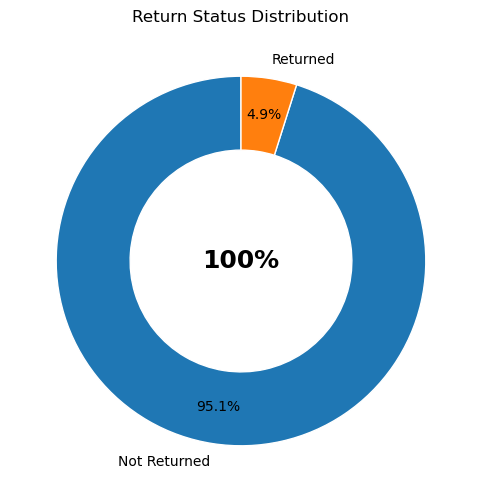

In [77]:
# Return status Distribution
returns_counts=df1["Returns"].value_counts().reindex([0,1],fill_value=0)

labels=['Not Returned','Returned']

plt.figure(figsize=(7,6))

plt.pie(
    returns_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'},
    pctdistance=0.8
)

plt.title('Return Status Distribution')
plt.text(0, 0, '100%', ha='center', va='center',
         fontsize=18, fontweight='bold')
plt.show()

## Margin Erosion Analysis
Sales grew 77% in 2020 but profit grew only 14%. The cells below find where the margin was lost.

In [ ]:
# 1) Margin by region and year
df['Year'] = df['Order Date'].dt.year

reg = df.pivot_table(index='Region', columns='Year', values=['Sales', 'Profit'], aggfunc='sum')
margin_region = (reg['Profit'] / reg['Sales'] * 100).round(2)
margin_region['Change'] = (margin_region[2020] - margin_region[2019]).round(2)
display(margin_region)

In [ ]:
# 2) Category share of yearly sales (product mix shift)
cat_sales = df.groupby(['Year', 'Category'])['Sales'].sum()
cat_share = (cat_sales / cat_sales.groupby(level=0).transform('sum') * 100).round(2)
display(cat_share.unstack('Year'))

In [ ]:
# 3) Sub-category margin 2019 vs 2020
sub = df.pivot_table(index='Sub-Category', columns='Year', values=['Sales', 'Profit'], aggfunc='sum')
margin_sub = (sub['Profit'] / sub['Sales'] * 100).round(2)
margin_sub['Change'] = (margin_sub[2020] - margin_sub[2019]).round(2)
display(margin_sub.sort_values(2020))

In [ ]:
# 4) Chart: margin by region, 2019 vs 2020
margin_region[[2019, 2020]].plot(kind='bar', figsize=(8, 5))
plt.title('Profit Margin by Region: 2019 vs 2020')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.legend(title='Year')
plt.show()

## Data Quality Check
Some rows have profit greater than sales, which is not possible in real retail. They are flagged here and the findings are re-tested without them.

In [ ]:
# Rows where profit is greater than sales
anomalies = df[df['Profit'] > df['Sales']]
print("Rows with Profit > Sales:", len(anomalies))
print("Their profit:", round(anomalies['Profit'].sum(), 2), "| their sales:", round(anomalies['Sales'].sum(), 2))
print("Share of total profit:", round(anomalies['Profit'].sum() / df['Profit'].sum() * 100, 1), "%")
display(anomalies[['Customer Name', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Profit']]
        .sort_values('Profit', ascending=False).head(5))

In [ ]:
# Re-test: margin by year and region without the anomalous rows
clean = df[df['Profit'] <= df['Sales']]

yearly_clean = clean.groupby('Year').agg(Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'))
yearly_clean['Margin_%'] = (yearly_clean['Total_Profit'] / yearly_clean['Total_Sales'] * 100).round(2)
display(yearly_clean.round(2))

reg_clean = clean.pivot_table(index='Region', columns='Year', values=['Sales', 'Profit'], aggfunc='sum')
margin_region_clean = (reg_clean['Profit'] / reg_clean['Sales'] * 100).round(2)
margin_region_clean['Change'] = (margin_region_clean[2020] - margin_region_clean[2019]).round(2)
display(margin_region_clean)

## Key Insights & Recommendations

**Insights**
1. **Growth without profit:** sales grew 77% ($564.7K to $1.0M) but profit only 14% ($81.8K to $93.4K), so overall margin fell from 14.5% to 9.3%.
2. **Product mix shift:** Office Supplies rose from 31.0% to 46.8% of sales while its margin fell from 20.0% to 8.5%. Binders (23.9% to 5.8%) and Paper (41.9% to 15.5%) drove most of it.
3. **Data quality:** 14 rows have profit greater than sales ($29.3K profit on $10.9K sales, about 17% of total profit), six of them Copiers. Without them, margin still falls from 11.9% to 8.0%, so the main finding holds.
4. **Regional gap:** South collapsed in both views (about 20.0% to 5.4%). Central looks like a collapse (16.5% to 3.4%), but its 2019 margin was inflated by the bad rows; without them it moves from 5.5% to 2.9%. East is stable and West slips from 13.0% to 10.8% without the bad rows.
5. **Loss-making products:** Tables worsened from -4.9% to -13.7% margin, and Machines turned negative (5.6% to -7.2%). In total, 1,098 line items lost $91.7K.
6. **Statistics:** region and payment mode are significantly related (chi-square p = 0.001) but the association is very weak (Cramer's V = 0.04). Shipping days has almost no correlation with sales or profit. Returns are 287 of 5,901 records (4.9%).

**Recommendations**
- Validate the source of profit figures before reporting, because a few bad rows can distort customer and regional rankings.
- Review pricing and costs on Tables and Machines.
- Investigate cost drivers in South (biggest margin drop) and Central (lowest margin, 2.9% in 2020 after cleaning).
- Protect margin on high-volume Office Supplies such as Binders and Paper.
- Track profit margin alongside sales, since sales growth alone hid the problem.